Spotify Dataset Analysis

* Step-1 Few Questions to see
- Are the most popular tracks (popularity > 90) universally optimized for the algorithm (high danceability, high energy, duration between 2.5 and 3.5 minutes), or are there successful "rebels" that break every rule?
- Do explicit tracks hold an overall popularity advantage, or is that "bump" entirely driven by a few dominant genres like Hip-Hop and Pop?
- Is there a measurable penalty for song length? How sharply does track popularity drop off once a song crosses the 3.5-minute mark compared to tracks under 2.5 minutes?


In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 

Step 2 - Loading and inspecting the data

In [4]:
df = pd.read_csv(r"C:\Users\Anbit Bhattarai\Desktop\Data_Analysis_Projects\01-spotify-tracks\spotify_dataset.csv")

pd.set_option("display.width",1000)

print("Top 5 of the Sheet: ")
print(df.head(5))

print("Bottom 5 of the Sheet:")
print(df.tail(5))

print("Seeded Random Sample: ")
print(df.sample(5, random_state=42))

print(df.shape)
# (114000, 24) 114000 rows and 24 columns

# To inspect non-null counts and dtypes in one go:
print(df.info())

print(df.dtypes)
print(df.isna().count())

# Unnamed: 0             114000
# Unnamed: 0.11          114000
# track_id               114000
# artists                114000
# album_name             114000
# track_name             114000
# popularity             114000
# duration_ms            114000
# explicit               114000
# danceability           114000
# energy                 114000
# key                    114000
# loudness               114000
# mode                   114000
# speechiness            114000
# acousticness           114000
# instrumentalness       114000
# liveness               114000
# valence                114000
# tempo                  114000
# time_signature         114000
# track_genre            114000
# duration in minutes    114000
# category               114000
# dtype: int64


print("Unique Track id without nan")
print(df["track_id"].nunique()) #For unique count


print("Unique Track id without nan")
print(df["track_id"].nunique(dropna= False))#For unique count dropping nan

# 89741
# 89741

print("Unique artists wihtout nan")
print(df["artists"].nunique())

print("Unique artists With nan")
print(df["artists"].nunique(dropna= False))

# Unique artists wihtout nan
# 31437
# Unique artists With nan
# 31437


print("Unique artists wihtout nan")
print(df["track_genre"].nunique())

print("Unique artists With nan")
print(df["track_genre"].nunique(dropna= False))

# Unique track genre wihtout nan
# 114
# Unique track genre With nan
# 114




Top 5 of the Sheet: 
   Unnamed: 0  Unnamed: 0.11                track_id                 artists                                         album_name                  track_name  popularity  duration_ms  explicit  danceability  ...  speechiness  acousticness  instrumentalness  liveness  valence    tempo  time_signature  track_genre  duration in minutes  category
0           0              0  5SuOikwiRyPMVoIQDJUgSV             Gen Hoshino                                             Comedy                      Comedy          73       230666     False        99.000  ...       0.1430        0.0322          0.000001    0.3580    0.715   87.917               4     acoustic             3.844433      High
1           1              1  4qPNDBW1i3p13qLCt0Ki3A            Ben Woodward                                   Ghost (Acoustic)            Ghost - Acoustic          55       149610     False         0.420  ...       0.0763        0.9240          0.000006    0.1010    0.267   77.489           

Step 2 - Cleaning the Data

In [5]:
missing_values = (df.isna().sum()/df.shape[0])*100
print(missing_values.sort_values(ascending= False))

# artists                0.000877
# album_name             0.000877
# track_name             0.000877
# Unnamed: 0             0.000000
# track_id               0.000000
# Unnamed: 0.11          0.000000
# popularity             0.000000
# duration_ms            0.000000
# explicit               0.000000
# danceability           0.000000
# energy                 0.000000
# key                    0.000000
# loudness               0.000000
# mode                   0.000000
# speechiness            0.000000
# acousticness           0.000000
# instrumentalness       0.000000
# liveness               0.000000
# valence                0.000000
# tempo                  0.000000
# time_signature         0.000000
# track_genre            0.000000
# duration in minutes    0.000000
# category               0.000000
# dtype: float64

df_unique_ids = df.drop_duplicates(subset= ["track_id"])
print(df.duplicated().sum())
print(df_unique_ids)


print(df)

artists                0.000877
album_name             0.000877
track_name             0.000877
Unnamed: 0             0.000000
track_id               0.000000
Unnamed: 0.11          0.000000
popularity             0.000000
duration_ms            0.000000
explicit               0.000000
danceability           0.000000
energy                 0.000000
key                    0.000000
loudness               0.000000
mode                   0.000000
speechiness            0.000000
acousticness           0.000000
instrumentalness       0.000000
liveness               0.000000
valence                0.000000
tempo                  0.000000
time_signature         0.000000
track_genre            0.000000
duration in minutes    0.000000
category               0.000000
dtype: float64
0
        Unnamed: 0  Unnamed: 0.11                track_id                 artists                                         album_name                  track_name  popularity  duration_ms  explicit  danceability  ... 

- Step 4: Univariate Analysis and Outliers



In [6]:
start_count = len(df_unique_ids)
print(f"Starting rows: {start_count}")

# 2. Run your first filter (popularity, duration, tempo)
df_unique_ids = df_unique_ids[
    (df_unique_ids["popularity"].between(0, 100)) &
    (df_unique_ids["duration_ms"] > 0) &
    (df_unique_ids["tempo"] > 0)
]


features_0_1 = [
    "danceability",
    "energy",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "mode"
]

mask = (df_unique_ids[features_0_1] >= 0) & (df_unique_ids[features_0_1] <= 1)

df_unique_ids = df_unique_ids[mask.all(axis=1)]
count_after_filter_1 = len(df_unique_ids)
print(f"Rows after basic filters: {count_after_filter_1} (Dropped: {start_count - count_after_filter_1})")

Starting rows: 89741


Rows after basic filters: 89582 (Dropped: 159)


In [10]:
popularity_data = df_unique_ids["popularity"].dropna()

popularity_data_mean = popularity_data.mean()
popularity_data_median = popularity_data.median()

print(popularity_data_mean)
print(popularity_data_median)

33.19135540622
33.0


'-' or 'solid' — Solid line (default)

'--' or 'dashed' — Dashed line (- - - -)

'-.' or 'dashdot' — Alternating dash and dot (- . - .)

':' or 'dotted' — Dotted line (. . . . .)

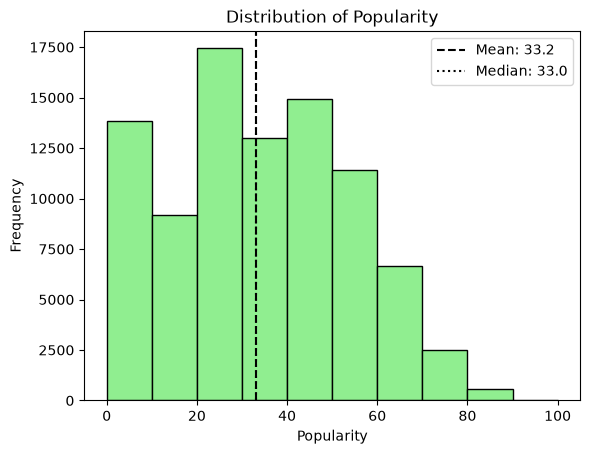

0.07150343083983735


In [25]:
plt.hist(df_unique_ids["popularity"],color= "lightgreen",ec ="Black")

plt.axvline(popularity_data_mean,linestyle = "--",color = "Black",label = f'Mean: {popularity_data_mean:.1f}')
plt.axvline(popularity_data_median,linestyle = ":",color = "Black",label = f'Median: {popularity_data_median:.1f}')


plt.title("Distribution of Popularity")
plt.xlabel("Popularity")
plt.ylabel("Frequency")
plt.legend()  
plt.show()

print(df_unique_ids["popularity"].skew())

Q1: 173160.0
Q2 (Median): 213386.0
Q3: 264360.0
IQR: 91200.0
Upper Limit: 401160.0
Lower Limit: 36360.0
Duration outliers: 4221
Tempo outliers: 34
Loudness outliers: 1954


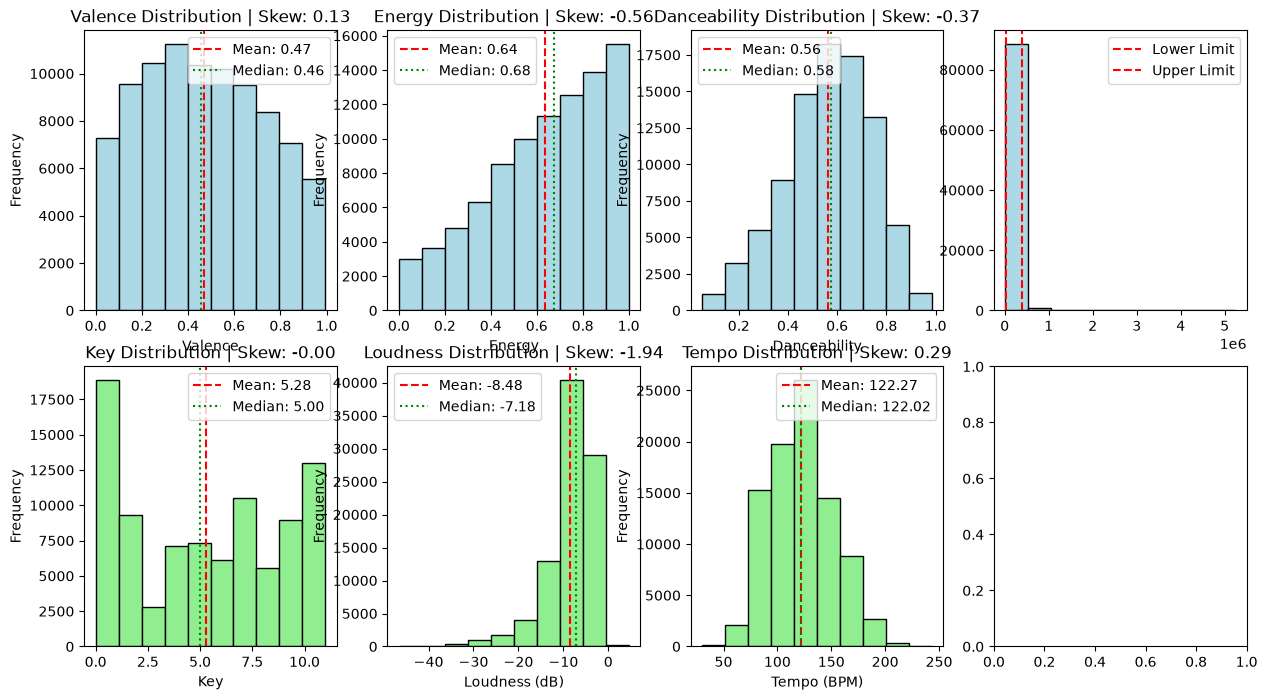

In [55]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(15, 8))

v_mean, v_med, v_skew = df_unique_ids["valence"].mean(), df_unique_ids["valence"].median(), df_unique_ids["valence"].skew()
axes[0, 0].hist(df_unique_ids["valence"], color="lightblue", ec="black")
axes[0, 0].axvline(v_mean, color="red", linestyle="--", label=f"Mean: {v_mean:.2f}")
axes[0, 0].axvline(v_med, color="green", linestyle=":", label=f"Median: {v_med:.2f}")
axes[0, 0].set_title(f"Valence Distribution | Skew: {v_skew:.2f}")
axes[0, 0].set_xlabel("Valence")
axes[0, 0].set_ylabel("Frequency")
axes[0, 0].legend()

e_mean, e_med, e_skew = df_unique_ids["energy"].mean(), df_unique_ids["energy"].median(), df_unique_ids["energy"].skew()
axes[0, 1].hist(df_unique_ids["energy"], color="lightblue", ec="black")
axes[0, 1].axvline(e_mean, color="red", linestyle="--", label=f"Mean: {e_mean:.2f}")
axes[0, 1].axvline(e_med, color="green", linestyle=":", label=f"Median: {e_med:.2f}")
axes[0, 1].set_title(f"Energy Distribution | Skew: {e_skew:.2f}")
axes[0, 1].set_xlabel("Energy")
axes[0, 1].set_ylabel("Frequency")
axes[0, 1].legend()

d_mean, d_med, d_skew = df_unique_ids["danceability"].mean(), df_unique_ids["danceability"].median(), df_unique_ids["danceability"].skew()
axes[0, 2].hist(df_unique_ids["danceability"], color="lightblue", ec="black")
axes[0, 2].axvline(d_mean, color="red", linestyle="--", label=f"Mean: {d_mean:.2f}")
axes[0, 2].axvline(d_med, color="green", linestyle=":", label=f"Median: {d_med:.2f}")
axes[0, 2].set_title(f"Danceability Distribution | Skew: {d_skew:.2f}")
axes[0, 2].set_xlabel("Danceability")
axes[0, 2].set_ylabel("Frequency")
axes[0, 2].legend()

k_mean, k_med, k_skew = df_unique_ids["key"].mean(), df_unique_ids["key"].median(), df_unique_ids["key"].skew()
axes[1, 0].hist(df_unique_ids["key"], color="lightgreen", ec="black")
axes[1, 0].axvline(k_mean, color="red", linestyle="--", label=f"Mean: {k_mean:.2f}")
axes[1, 0].axvline(k_med, color="green", linestyle=":", label=f"Median: {k_med:.2f}")
axes[1, 0].set_title(f"Key Distribution | Skew: {k_skew:.2f}")
axes[1, 0].set_xlabel("Key")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].legend()

l_mean, l_med, l_skew = df_unique_ids["loudness"].mean(), df_unique_ids["loudness"].median(), df_unique_ids["loudness"].skew()
axes[1, 1].hist(df_unique_ids["loudness"], color="lightgreen", ec="black")
axes[1, 1].axvline(l_mean, color="red", linestyle="--", label=f"Mean: {l_mean:.2f}")
axes[1, 1].axvline(l_med, color="green", linestyle=":", label=f"Median: {l_med:.2f}")
axes[1, 1].set_title(f"Loudness Distribution | Skew: {l_skew:.2f}")
axes[1, 1].set_xlabel("Loudness (dB)")
axes[1, 1].set_ylabel("Frequency")
axes[1, 1].legend()

t_mean, t_med, t_skew = df_unique_ids["tempo"].mean(), df_unique_ids["tempo"].median(), df_unique_ids["tempo"].skew()
axes[1, 2].hist(df_unique_ids["tempo"], color="lightgreen", ec="black")
axes[1, 2].axvline(t_mean, color="red", linestyle="--", label=f"Mean: {t_mean:.2f}")
axes[1, 2].axvline(t_med, color="green", linestyle=":", label=f"Median: {t_med:.2f}")
axes[1, 2].set_title(f"Tempo Distribution | Skew: {t_skew:.2f}")
axes[1, 2].set_xlabel("Tempo (BPM)")
axes[1, 2].set_ylabel("Frequency")
axes[1, 2].legend()

#IQR ooutliers for duration and z-score for tempo and loudness

q1, q2, q3 = np.percentile(
    df_unique_ids["duration_ms"].dropna(),
    [25, 50, 75]
)

InQuRa = q3 - q1

UL = q3 + 1.5 * InQuRa
LL = q1 - 1.5 * InQuRa

print("Q1:", q1)
print("Q2 (Median):", q2)
print("Q3:", q3)
print("IQR:", InQuRa)
print("Upper Limit:", UL)
print("Lower Limit:", LL)

axes[0, 3].hist(
    df_unique_ids["duration_ms"].dropna(),
    color="lightblue",
    ec="black"
)

axes[0, 3].axvline(LL, color="red", linestyle="--", label="Lower Limit")
axes[0, 3].axvline(UL, color="red", linestyle="--", label="Upper Limit")
axes[0, 3].legend()

outliers = df_unique_ids[
    (df_unique_ids["duration_ms"] < LL) |
    (df_unique_ids["duration_ms"] > UL)
]

print("Duration outliers:", len(outliers))
tempo_z = (
    (df_unique_ids["tempo"] - df_unique_ids["tempo"].mean()) /
    df_unique_ids["tempo"].std()
)

loudness_z = (
    (df_unique_ids["loudness"] - df_unique_ids["loudness"].mean()) /
    df_unique_ids["loudness"].std()
)

df_unique_ids["tempo_outlier"] = tempo_z.abs() > 3
df_unique_ids["loudness_outlier"] = loudness_z.abs() > 3

print("Tempo outliers:", df_unique_ids["tempo_outlier"].sum())
print("Loudness outliers:", df_unique_ids["loudness_outlier"].sum())